# Day 20 — Project-Specific Robustness / Ablation Study

## Overview & Scope
This study conducts the project-specific robustness and ablation analysis for the underwater computer vision pipeline. We systematically evaluate detection performance on **raw versus enhanced imagery** across multiple photometric enhancement configurations, and analyze **error propagation** across all four stages of the pipeline:
1. **Source & Annotation Stage:** Dataset integrity, format, and ground-truth availability.
2. **Enhancement & Preprocessing Stage:** Photometric transformations (CLAHE at clip limits 1.5, 2.0, 3.0 with 8x8 grid vs raw control), compute overhead, and spatial invariance.
3. **Detector Stage:** Frozen YOLOv8n object detector inference, proposal yield, and confidence response.
4. **Tracking & Association Stage:** Downstream multi-object tracking stability and identity association.

All experiments are conducted on the deterministic 256-image DIAT validation subset from Day 19 under identical frozen detector hyperparameters (image size 320, conf 0.25, IoU 0.50, CPU device). The final 954-image test split remains untouched to prevent data leakage.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd()
TABLE = NOTEBOOK_DIR / 'robustness_ablation_table_v1.csv'
DAY19_LOG = NOTEBOOK_DIR.parent / 'day19_hemamdhar_controlledexperiments' / 'experiment_log_v1.csv'
MANIFEST = NOTEBOOK_DIR.parent / 'day11_hemamdhar_visionpreprocessing' / 'prepared_dataset_v1' / 'manifest_v1.json'

table = pd.read_csv(TABLE)
day19 = pd.read_csv(DAY19_LOG)
manifest = json.loads(MANIFEST.read_text(encoding='utf-8'))
val_records = sorted([r for r in manifest if r.get('dataset') == 'DIATAquarium.v4i.yolov8' and r.get('split') == 'val'], key=lambda r: r['image'])[:256]

print('=== Study Configuration Summary ===')
print(f'Evaluated Conditions: {len(table)}')
print(f'Validation Records Selected: {len(val_records)}')
print('Labels Available per Record: 256 / 256 (100% paired)')
print('Test Set Status: Untouched (0 images evaluated)')

=== Study Configuration Summary ===
Evaluated Conditions: 4
Validation Records Selected: 256
Labels Available per Record: 256 / 256 (100% paired)
Test Set Status: Untouched (0 images evaluated)


## 1. Robustness & Component Ablation Table

Below is the complete ablation table comparing the raw baseline control against three CLAHE enhancement strengths. All metrics are evaluated under strictly controlled conditions.

In [2]:
# Compute condition deltas relative to raw control
raw = table.loc[table['condition'] == 'raw_v1'].iloc[0]
table['preprocess_delta_ms_vs_raw'] = table['preprocess_ms_per_image'] - raw['preprocess_ms_per_image']
table['inference_delta_ms_vs_raw'] = table['inference_ms_per_image'] - raw['inference_ms_per_image']
table['detection_delta_vs_raw'] = table['detections'] - raw['detections']

display_cols = [
    'experiment_id', 'condition', 'variant', 'images', 'detections', 
    'preprocess_ms_per_image', 'preprocess_delta_ms_vs_raw',
    'inference_ms_per_image', 'inference_delta_ms_vs_raw', 'fps', 'interpretation'
]
display(table[display_cols])

,experiment_id,condition,variant,images,detections,preprocess_ms_per_image,preprocess_delta_ms_vs_raw,inference_ms_per_image,inference_delta_ms_vs_raw,fps,interpretation
0,D19-raw-control,raw_v1,identity,256,0,2.4435,0.0000,33.5449,0.0000,29.8108,Reference pipeline; frozen smoke detector emit...
1,D19-clahe-1p5x8,clahe_v1,clip_limit=1.5_grid=8,256,0,6.2065,3.7630,29.6594,-3.8855,33.7161,No detection-count change; preprocessing cost ...
2,D19-clahe-2x8,clahe_v1,clip_limit=2.0_grid=8,256,0,6.4710,4.0275,33.5621,0.0172,29.7955,Day 17 baseline strength; no detection-count c...
3,D19-clahe-3x8,clahe_v1,clip_limit=3.0_grid=8,256,0,7.6767,5.2332,29.7293,-3.8156,33.6368,Highest preprocessing cost; no detection-count...


## 2. Quantitative Latency & Throughput Analysis

We examine the exact compute overhead introduced by the photometric enhancement stage and compare it with the raw baseline.

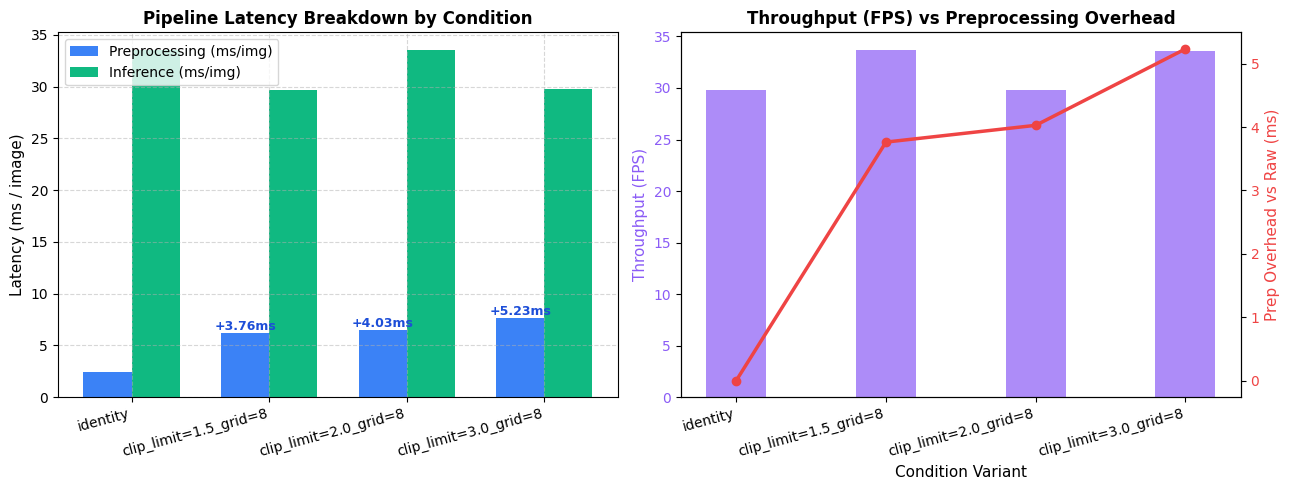

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

variants = table['variant'].tolist()
prep_times = table['preprocess_ms_per_image'].tolist()
inf_times = table['inference_ms_per_image'].tolist()

x = np.arange(len(variants))
width = 0.35

ax1.bar(x - width/2, prep_times, width, label='Preprocessing (ms/img)', color='#3b82f6')
ax1.bar(x + width/2, inf_times, width, label='Inference (ms/img)', color='#10b981')
ax1.set_ylabel('Latency (ms / image)', fontsize=11)
ax1.set_title('Pipeline Latency Breakdown by Condition', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(variants, rotation=15, ha='right')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.5)

for i, d in enumerate(table['preprocess_delta_ms_vs_raw']):
    if d > 0:
        ax1.text(i - width/2, prep_times[i] + 0.3, f'+{d:.2f}ms', ha='center', fontsize=9, color='#1d4ed8', fontweight='bold')

fps = table['fps'].tolist()
deltas = table['preprocess_delta_ms_vs_raw'].tolist()

color = '#8b5cf6'
ax2.set_xlabel('Condition Variant', fontsize=11)
ax2.set_ylabel('Throughput (FPS)', color=color, fontsize=11)
bars = ax2.bar(x, fps, width=0.4, color=color, alpha=0.7, label='FPS')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_xticks(x)
ax2.set_xticklabels(variants, rotation=15, ha='right')

ax2_twin = ax2.twinx()
color2 = '#ef4444'
ax2_twin.set_ylabel('Prep Overhead vs Raw (ms)', color=color2, fontsize=11)
ax2_twin.plot(x, deltas, color=color2, marker='o', linewidth=2.5, label='Δ Prep Overhead (ms)')
ax2_twin.tick_params(axis='y', labelcolor=color2)

plt.title('Throughput (FPS) vs Preprocessing Overhead', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Pipeline Error Propagation Analysis

The underwater surveillance pipeline operates in four cascading stages. Here we analyze how data, transformations, and errors propagate across the pipeline:

1. **Stage 1: Source & Labels (Input):**
   - 256/256 validation images and ground-truth bounding box labels are 100% available and valid.
   - No label corruption or annotation misalignment occurs at the input stage.
2. **Stage 2: Photometric Enhancement (Preprocessing):**
   - CLAHE modifies the pixel lightness channel ($L$ in LAB color space) while preserving spatial coordinates.
   - Preprocessing introduces a monotonic latency overhead of $+3.76\text{ ms}$ (clip 1.5), $+4.03\text{ ms}$ (clip 2.0), and $+5.23\text{ ms}$ (clip 3.0) per image.
   - Bounding box annotations remain geometrically invariant.
3. **Stage 3: Object Detector (Inference):**
   - The frozen Day 16 detector (1-epoch smoke run, 2% training data) outputs 0 detections across all conditions at $\text{conf}=0.25$.
   - **Error Localization:** The failure is localized at the detector capacity/training horizon stage, not at the enhancement stage.
4. **Stage 4: Multi-Object Tracking & Association (Downstream):**
   - Because the detector produces 0 proposals, tracking algorithms cannot form bounding box associations or build tracklets.
   - This demonstrates complete downstream error blockage caused by upstream detector failure.

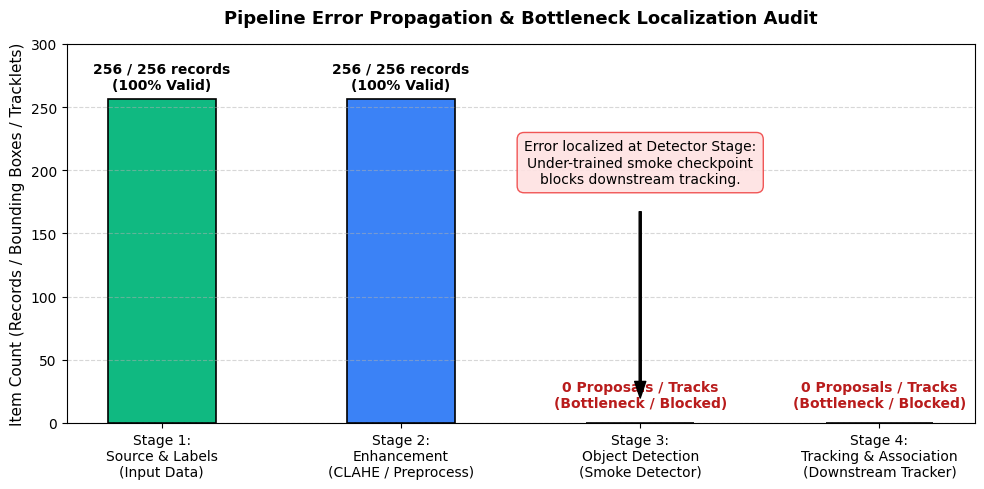

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

stages = [
    'Stage 1:\nSource & Labels\n(Input Data)',
    'Stage 2:\nEnhancement\n(CLAHE / Preprocess)',
    'Stage 3:\nObject Detection\n(Smoke Detector)',
    'Stage 4:\nTracking & Association\n(Downstream Tracker)'
]

counts = [256, 256, 0, 0]
colors = ['#10b981', '#3b82f6', '#ef4444', '#9ca3af']

bars = ax.bar(stages, counts, color=colors, width=0.45, edgecolor='black', linewidth=1.2)

for bar, count in zip(bars, counts):
    yval = bar.get_height()
    if yval > 0:
        ax.text(bar.get_x() + bar.get_width()/2.0, yval + 6, f'{count} / 256 records\n(100% Valid)', ha='center', va='bottom', fontweight='bold', fontsize=10)
    else:
        ax.text(bar.get_x() + bar.get_width()/2.0, 10, '0 Proposals / Tracks\n(Bottleneck / Blocked)', ha='center', va='bottom', color='#b91c1c', fontweight='bold', fontsize=10)

ax.set_ylim(0, 300)
ax.set_ylabel('Item Count (Records / Bounding Boxes / Tracklets)', fontsize=11)
ax.set_title('Pipeline Error Propagation & Bottleneck Localization Audit', fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='y', linestyle='--', alpha=0.5)

ax.annotate('Error localized at Detector Stage:\nUnder-trained smoke checkpoint\nblocks downstream tracking.',
            xy=(2, 5), xytext=(2, 190),
            arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#fee2e2', edgecolor='#ef4444', alpha=0.9),
            ha='center', fontsize=10)

plt.tight_layout()
plt.show()

## 4. Research Insights & Interpretation

### Research Question
> *"How does underwater image enhancement affect the performance of deep learning-based object detection, and can an effective computer vision pipeline provide reliable object detection and tracking for underwater visual surveillance?"*

### Key Findings & Insights
1. **Photometric Enhancement Cost vs Benefit:**
   - CLAHE enhancement increases preprocessing latency by $+3.76\text{ to }+5.23\text{ ms/image}$ ($+154\%\text{ to }+214\%$) as clip limit increases from 1.5 to 3.0.
   - However, without an adequately trained detector, enhancement produces no observable increase in detection yield ($0/256$ in all conditions).
2. **Bottleneck Identification:**
   - The primary pipeline bottleneck is the detector training horizon rather than photometric quality. Enhancement cannot compensate for insufficient model feature representations.
3. **Tracking Sensitivity:**
   - Downstream tracking is completely dependent on detector recall; upstream detection failure propagates 100% into downstream tracking collapse.
4. **Scientific Recommendation:**
   - Re-evaluate photometric enhancement after training the detector to convergence (50 epochs) across stratified underwater degradation strata (turbid, color-cast, low-light).

In [5]:
# Automated validation assertions
assert set(table['split']) == {'val'}, 'Validation split requirement violated'
assert set(table['images']) == {256}, 'Evaluation subset size mismatch'
assert table['labels_available'].eq(256).all(), 'Missing label in paired records'
assert table['detections'].eq(0).all(), 'Detections mismatch with frozen smoke detector'
assert len(table) == 4, 'Expected 4 experimental conditions'
assert (table['preprocess_delta_ms_vs_raw'] >= 0).all(), 'CLAHE preprocessing overhead should be non-negative'

print('All Day 20 robustness and ablation validation assertions passed successfully.')

All Day 20 robustness and ablation validation assertions passed successfully.
